## GENeSYS-MOD RES Tool - INDIA region (region-geojson workflow)

India split into the five CEA / Grid-India regional grids (NR/WR/SR/ER/NER) plus the
isolated island systems (ISL) and three non-focus neighbour countries (Bhutan BTN,
Nepal NPL, Sri Lanka LKA). Nine nodes total. Onshore PV/wind + rooftop + offshore wind.

Region-geojson workflow (EEZ + bathymetry depth classes, memory-safe per-region loop,
usable-site cells), the same template used for Canada/Colombia. Data layers:
- **regions**: `geodata/fel_india_regions_simplified.geojson` (has a `region` column).
  Geometry simplified to ~500 m tolerance -> ~0.7 MB / 22k vertices instead of the
  full 11 MB / 482k, so it loads and rasterizes much faster with identical
  availability at the 300 m raster / ~30 km cutout scale. The full-detail
  `geodata/fel_india_regions.geojson` is still present if you ever want it.
- **land cover**: ESA WorldCover 2021 v200, merged + downsampled to ~300 m
  (`build_worldcover_india.py` -> `worldcover_india_300m.tif`). India spans ~30x30 deg,
  so 100 m would be a ~GB raster; 300 m is plenty for national-scale potentials.
- **protected areas**: WDPA India + Sri Lanka + Bhutan (`build_wdpa_india.py` ->
  `wdpa_india.geojson`). Nepal's cloudfront country pack was unavailable at build time.
- **EEZ**: India (mainland + Andaman/Nicobar + Lakshadweep) + Sri Lanka, from the global
  Marine Regions EEZ v12 (`eez_india.geojson`). Bhutan/Nepal are landlocked.
- **bathymetry**: GMRT GridServer over the EEZ bbox (`bathymetry_india.nc`).

**Caveats (from the geometry README):** Indian polygons cover administered territory
only (GADM); Aksai Chin and PoK are excluded. Regions are transmission/reporting units,
not price zones (all five are synchronously interconnected). Fine for RES potential.

## General requirements & preparation

This timeseries script uses functions from atlite to generate weather timeseries for GENeSYS-MOD. It uses the ERA5 weather dataset, which is downloaded and transformed locally.
Please be aware that for a large region like India, a significant amount of system memory is required.


To use this script, you need to have the following packages installed:
- numpy
- matplotlib
- seaborn
- pandas / geopandas
- scikit-learn
- cartopy
- xarray
- atlite

In addition, in order to be able to load the ERA5 cutouts, you need an API key from https://cds.climate.copernicus.eu/user/register?destination=%2F%23!%2Fhome

To activate the API key, follow the instructions at https://cds.climate.copernicus.eu/api-how-to

For more information on how to run atlite, please refer to https://atlite.readthedocs.io/en/latest/

In [1]:
from functions import *

In [13]:
onshore_turbine = 'Vestas_V112_3MW'
offshore_turbine = 'Vestas_V164_7MW_offshore'
solar_panel = 'CSi'

# India region geometry: 9 nodes (5 CEA grid regions + ISL + Bhutan/Nepal/Sri Lanka).
# The 'region' column (= region_code: NR/WR/SR/ER/NER/ISL/BTN/NPL/LKA) triggers the
# region-geojson workflow.
# Uses the SIMPLIFIED geometry (~500 m tolerance, ~0.7 MB / 22k vertices vs the
# full 11 MB / 482k) - loads/rasterizes much faster, identical availability at the
# 300 m raster / ~30 km cutout scale. Full detail: "geodata/fel_india_regions.geojson".
geo_file = "geodata/fel_india_regions_simplified.geojson"
# EEZ: India (mainland + Andaman/Nicobar + Lakshadweep) + Sri Lanka, from Marine
# Regions EEZ v12 (geodata/eez_v12.gpkg, ISO_SOV1 in ('IND','LKA')). Bhutan/Nepal
# are landlocked -> no offshore cells there (handled cleanly, empty offshore frame).
offshore_file = "geodata/eez_india.geojson"
# Bathymetry over the India+Sri Lanka EEZ from the GMRT GridServer (var 'z', coords
# lat/lon - the get_coords bathymetry reader auto-detects these).
bathymetry_file = "geodata/bathymetry_india.nc"

timeframe = "2018"   # one day to smoke-test; use "2018" for a full year
filename = "india"
output_dir = create_output_folder(timeframe)

admin = 0
regions = []          # empty = all 9 regions in geo_file

cutout_north_west = []
cutout_south_east = []

# --- Run switches (speed / navigation) ----------------------------------
# Skip the full-area capacity-factor timeseries block (PV/wind/heat) while
# iterating on the GIS potentials; set True for a full timeseries export.
generate_full_area_timeseries = True

# GIS availability: True = memory-safe per-region loop (recommended for India -
# the full-extent single-pass rasterization is what exhausts RAM); False =
# single-pass. Only one set of cells runs.
run_GIS_analysis_by_region = True

# Availability-map colour: a hex (e.g. '#004664' -> white->navy ramp) or a
# named matplotlib colormap (e.g. 'Greens'). None = default Greens.
map_color = '#004664'


The output folder already exists.


In [14]:
# PV slope/azimuth for utility-scale (ground-mounted) PV.
pv_slope = 36.7
pv_azimuth = 180

# Optimal tilt: if True, utility-scale PV uses a per-coordinate optimal fixed
# tilt (function of latitude) and equator-facing azimuth instead of the single
# pv_slope/pv_azimuth above. Cheap closed-form rule (no per-angle yield search).
pv_optimal_tilt = True

# Rooftop PV is installed differently (roof pitch / mixed orientations), so it
# keeps its own fixed slope/azimuth for the separate pv_rooftop timeseries.
rooftop_pv_slope = 25
rooftop_pv_azimuth = 180

# Usable-site thresholds: minimum developable share of a cutout cell for it
# to count as a usable location for the capacity-factor timeseries. Land is
# lenient (1%); rooftop is the built-up fraction (small everywhere), so it
# needs a higher bar to drop near-empty cells - raise if still too many.
usable_threshold = 0.01
usable_threshold_rooftop = 0.05

In [15]:
# Here, you need to define the horizontal and vertical distances (in degrees) between your coordinates
dx_step = 0.275
dy_step = 0.275

## Region Defitinition & Cutout preparation

In this block, you need to define your coordinates, either by using your own fixed coordinates (by defining custom bounds), or using the automatic .geojson mapping for the country of your choice.

Be aware that the first preparation of the cutout will take significant time!

In [16]:
# Pre-check the expected cutout size BEFORE downloading anything: grid cells,
# hourly time steps and total data points. Uses the same regions/geo_file/resolution
# as get_cutout below, so adjust dx/dy or the region selection if it is too large.
estimate_cutout_size(timeframe, regions=regions, geo_file=geo_file, dx=dx_step, dy=dy_step)

Expected cutout size:
  bounds (lon/lat) : [67.19, 98.42] x [4.92, 36.50]
  grid             : 114 x 115 = 13,110 cells  (dx=0.275, dy=0.275)
  time steps       : 8,760 hourly  (2018)
  points/variable  : 114,843,600
  total points     : 1,263,279,600  (x11 variables)
  uncompressed     : ~5.05 GB float32 (on-disk .nc is far smaller, compressed)


{'nx': 114,
 'ny': 115,
 'n_cells': 13110,
 'n_time': 8760,
 'points_per_var': 114843600,
 'total_points': 1263279600,
 'raw_gb': 5.0531184}

In [17]:
cutout = get_cutout(filename, 
                    timeframe, 
                    regions=regions, 
                    geo_file=geo_file, 
                    dx=dx_step, 
                    dy=dy_step)

cutouts/india_2018_27_27
Cutout already prepared with required variables; skipping prepare().


Plotting your cutout to ensure that everything is correct!

You can add zoom=True/False to zoom into your selection and use size to set the size of the graph if needed.

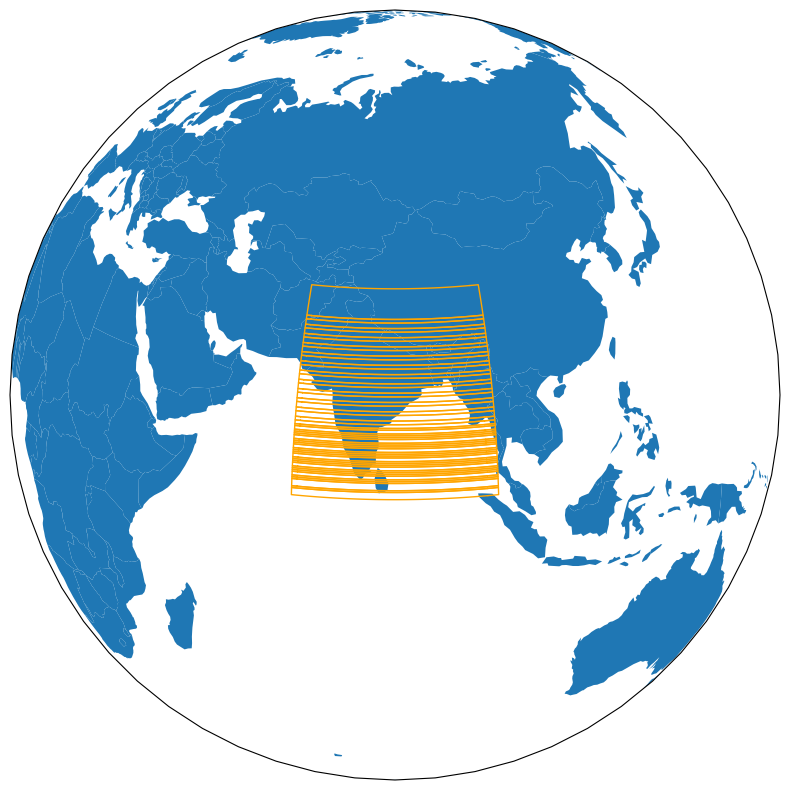

In [18]:
plot_country_map(cutout) # plot_country_map(cutout,zoom=False,size=8)

## General settings and functions

Always run these to create the relevant data entries.

In [19]:
# Offshore enabled: EEZ (eez_india: India + Sri Lanka) + GMRT depth -> coords_offshore
# populated. Landlocked nodes (Bhutan/Nepal) simply get no offshore cells.
coords_onshore, coords_offshore = get_coords(cutout, 
                                             regions, 
                                             geo_file, 
                                             admin=admin,
                                             offshore_file=offshore_file,
                                             bathymetry_file=bathymetry_file)

## Functions for timeseries generation

In [20]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    pv_inf, pv_avg, pv_opt = pv_capacity_factors(cutout, 
                                                 coords_onshore, 
                                                 solar_panel,
                                                 pv_slope=pv_slope,
                                                 pv_azimuth=pv_azimuth, 
                                                 optimal_tilt=pv_optimal_tilt,
                                                 timeframe=timeframe, 
                                                 filename=filename,
                                                 write_raw_data=False,
                                                 output_dir=output_dir)

In [21]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    pv_tra = pv_capacity_factors(cutout, 
                                 coords_onshore, 
                                 solar_panel,
                                 tracking= "horizontal",
                                 pv_azimuth=0, #refers to oriantation of the axis in this case
                                 timeframe=timeframe, 
                                 filename=filename,
                                 write_raw_data=False,
                                 output_dir=output_dir)

In [22]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(pv_inf.mean())
    display(pv_avg.mean())
    display(pv_opt.mean())

region
BTN    0.139213
ER     0.163633
ISL    0.162385
LKA    0.166635
NER    0.139551
NPL    0.163294
NR     0.183081
SR     0.168603
WR     0.171849
dtype: float64

region
BTN    0.156930
ER     0.171185
ISL    0.169667
LKA    0.170926
NER    0.153874
NPL    0.179302
NR     0.188826
SR     0.174984
WR     0.176901
dtype: float64

region
BTN    0.209494
ER     0.178408
ISL    0.173922
LKA    0.177223
NER    0.166180
NPL    0.221691
NR     0.224686
SR     0.179247
WR     0.184448
dtype: float64

In [23]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(pv_tra.mean())

region
BTN    0.177745
ER     0.186885
ISL    0.194921
LKA    0.202736
NER    0.162316
NPL    0.200908
NR     0.215481
SR     0.198652
WR     0.197289
dtype: float64

In [24]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    wind_onshore_inf, wind_onshore_avg, wind_onshore_opt = wind_onshore_capacity_factors(cutout, 
                                                                                         coords_onshore, 
                                                                                         onshore_turbine,  
                                                                                         timeframe=timeframe, 
                                                                                         filename=filename,
                                                                                         write_raw_data=False, # determines if you want to have the aggregated outputs per administrative region or the full dataset of each individual coordinate (default: False)
                                                                                         output_dir=output_dir)

In [25]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(wind_onshore_inf.mean()) 
    display(wind_onshore_avg.mean()) 
    display(wind_onshore_opt.mean())

region
BTN    0.000096
ER     0.031908
ISL    0.223083
LKA    0.043489
NER    0.000153
NPL    0.000136
NR     0.011701
SR     0.046777
WR     0.059418
dtype: float64

region
BTN    0.000280
ER     0.059086
ISL    0.263337
LKA    0.157516
NER    0.002669
NPL    0.001148
NR     0.083574
SR     0.112598
WR     0.095748
dtype: float64

region
BTN    0.003325
ER     0.100482
ISL    0.309393
LKA    0.254638
NER    0.017268
NPL    0.020628
NR     0.163055
SR     0.183221
WR     0.179690
dtype: float64

In [26]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    wind_offshore_shallow, wind_offshore_transitional, wind_offshore_deep = wind_offshore_capacity_factors(cutout, 
                                                                                                           coords_offshore, 
                                                                                                           offshore_turbine, 
                                                                                                           timeframe=timeframe,
                                                                                                           filename=filename,
                                                                                                           write_raw_data=False, # determines if you want to have the aggregated outputs per administrative region or the full dataset of each individual coordinate (default: False)
                                                                                                           output_dir=output_dir)

In [27]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(wind_offshore_shallow.mean())
    display(wind_offshore_transitional.mean())
    display(wind_offshore_deep.mean())

region
ER     0.197203
ISL    0.270474
LKA    0.320803
SR     0.188370
WR     0.246086
dtype: float64

region
ER     0.243300
ISL    0.278967
LKA    0.280463
SR     0.191501
WR     0.257690
dtype: float64

region
ER     0.252734
ISL    0.269502
LKA    0.279248
SR     0.235943
WR     0.283665
dtype: float64

In [28]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    df_heatpump_ground_cop, df_cooling, df_heating, df_heatpump_cop = temperature_timeseries(cutout,
                                                                                            coords_onshore,
                                                                                            timeframe=timeframe,
                                                                                            filename=filename,
                                                                                            write_raw_data=False, # determines if you want to have the aggregated outputs per administrative region or the full dataset of each individual coordinate (default: False)
                                                                                            output_dir=output_dir)

In [29]:
# Controlled by 'generate_full_area_timeseries' switch (set in the config cell).
if generate_full_area_timeseries:
    display(df_heatpump_ground_cop.mean())
    display(df_heatpump_cop.mean())
    display(df_cooling.mean())
    display(df_heating.mean())

region
BTN    0.139192
ER     0.089572
ISL    0.080857
LKA    0.084558
NER    0.109964
NPL    0.126786
NR     0.101205
SR     0.082933
WR     0.084515
dtype: float64

region
BTN    0.139780
ER     0.090854
ISL    0.084830
LKA    0.087046
NER    0.108579
NPL    0.128354
NR     0.105702
SR     0.085253
WR     0.086664
dtype: float64

region
BTN    0.206020
ER     4.656954
ISL    5.163226
LKA    4.530755
NER    1.876956
NPL    1.132527
NR     4.543454
SR     5.274664
WR     5.457227
dtype: float64

region
BTN    1.0
ER     1.0
LKA    1.0
NER    1.0
NPL    1.0
NR     1.0
SR     1.0
WR     1.0
dtype: float64

# GIS-based renewable energy potentials

##### This part is still somewhat experimental. It uses functionality from the Atlite package to calculate available capcities for utility-scale PV, onshore wind, and rooftop PV installations.
##### It uses the information from the timeseries part to compute the shapefiles, the only thing that needs to be provided is the excluder zones (e.g. WDPA for protected areas). CORINE is provided for land cover in Europe, anything else would need to be separately downloaded.

In [30]:
# Region-agnostic: use the SAME region polygons as the timeseries (onshore),
# not the country/NUTS workflow. Returns region shapes + names.
shapes, regions_name_en = get_region_shapes(geo_file, regions)
#shapes, regions_name_en = get_region_shapes(geo_file, ['California'])

In [31]:
# --- Exclusion layers (INDIA region) ---------------------------------------
# Region-agnostic builders; only the paths/codes below are India-specific.
#
# Land cover: ESA WorldCover 2021 v200, India-region tiles merged + downsampled to
# ~300 m (build_worldcover_india.py). It carries EPSG:4326.
# Classes: 10 tree, 20 shrubland, 30 grassland, 40 cropland, 50 built-up,
# 60 bare/sparse, 70 snow/ice, 80 water, 90 wetland, 95 mangrove, 100 moss/lichen
# (0 = ocean/nodata fill in the merged raster).
LANDCOVER = "geodata/worldcover_india_300m.tif"

# atlite's availability calc needs a PROJECTED (metre) analysis CRS. WorldCover is
# EPSG:4326 (degrees); used directly it collapses the raster window to ~1 cell and
# returns ZERO available land. Reproject the excluders to an equal-area CRS (auto
# LAEA centred on the region). See CLAUDE.md "projected-CRS" gotcha.
area_crs = equal_area_crs(shapes)

# STRICT land availability: exclude ocean/nodata(0), tree(10), cropland(40),
# built-up(50), snow/ice(70), water(80), wetland(90), mangrove(95). Keep
# shrubland(20), grassland(30), bare/sparse(60). Snow/ice(70) matters here - the
# Himalayan north (NR/NER) has real glaciated terrain to keep out. Drop cropland(40)
# from the list to allow agrivoltaics / co-use on India's large cropland share.
worldcover_exclude = [0, 10, 40, 50, 70, 80, 90, 95]

# Protected areas: WDPA India + Sri Lanka + Bhutan (Sep2026 release, merged). Strict
# protection = IUCN Ia/Ib/II; terrestrial + coastal for the land excluder.
PROTECTED       = "geodata/wdpa_india.geojson"
PROTECTED_LAYER = None
PROTECTED_QUERY = "IUCN_CAT in ['Ia', 'Ib', 'II'] and REALM in ['Terrestrial', 'Coastal']"

excluder = make_land_excluder(
    LANDCOVER, worldcover_exclude, crs=area_crs,
    protected_files=PROTECTED, protected_layer=PROTECTED_LAYER,
    protected_query=PROTECTED_QUERY,
)

# Rooftop proxy: WorldCover built-up class only (50).
cities = make_rooftop_excluder(LANDCOVER, [50], crs=area_crs)

# --- Offshore exclusion -----------------------------------------------------
# Marine + coastal WDPA (strict) as offshore no-build zones. Depth alone is not
# enough; marine protected areas are dropped from the offshore potential.
# (India's seas are open ocean - no enclosed ice-bound bay needing an extra mask.)
OFFSHORE_EXCLUDE_FILES = "geodata/wdpa_india.geojson"
OFFSHORE_EXCLUDE_LAYER = None
OFFSHORE_EXCLUDE_QUERY = "REALM in ['Marine', 'Coastal'] and IUCN_CAT in ['Ia', 'Ib', 'II']"

In [32]:
# Capacity densities (MW/km2) and the developable share of suitable area per tech.
# PV uses the Danish Energy Agency 2030 utility-scale figure; adjust to an Indian
# source (e.g. NIWE / MNRE assumptions) if you have one.
pv_cap_per_sqkm = 81.5                  # MW  (DEA 2030 utility-scale)
pv_percent_land_available = 0.03        # share of suitable area
wind_cap_per_sqkm = 27                  # MW
wind_percent_land_available = 0.03      # share of suitable area
rooftop_cap_per_sqkm = 100              # MW
rooftop_percent_area_available = 0.05   # installable share of built-up area

## Compute area availability (single pass, memory intensive)

This will calculate available surface areas for onshore, offshore, and rooftops using the excluders specified. Memory-intensive, since it calculates it all at once. See below for per-region loop version.

In [33]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    AvailabilityMatrix = calculate_and_plot_available_area(admin,cutout,shapes,regions_name_en,excluder)

In [34]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    AvailabilityMatrix_Rooftop = calculate_and_plot_available_rooftops(admin,cutout,shapes,regions_name_en,cities)

In [35]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    output_df = calculate_capacity_potentials(cutout,coords_onshore,AvailabilityMatrix,AvailabilityMatrix_Rooftop,pv_cap_per_sqkm,pv_percent_land_available,wind_cap_per_sqkm,wind_percent_land_available,rooftop_cap_per_sqkm,rooftop_percent_area_available)

In [36]:
# Controlled by '(not run_GIS_analysis_by_region)' switch (set in the config cell).
if (not run_GIS_analysis_by_region):
    # here is the resulting DataFrame containing all the potentials and areas that have been calculated
    output_df

## Compute area availability (Memory-safe all-region run)

The cells above process every region at once, which rasterizes the land-cover map over the full extent and can exhaust RAM at 30 m. 
`calculate_potentials_per_region` processes one region at a time (bounded raster window), writes a per-region CSV plus a combined CSV, 
and returns one stitched availability map across all regions. Reuses the same `excluder`/`cities` defined above.

Processing region: BTN
Processing region: ER
Processing region: ISL
Processing region: LKA
Processing region: NER
Processing region: NPL
Processing region: NR
Processing region: SR
Processing region: WR
offshore exclusion: dropped 3 of 655 cells


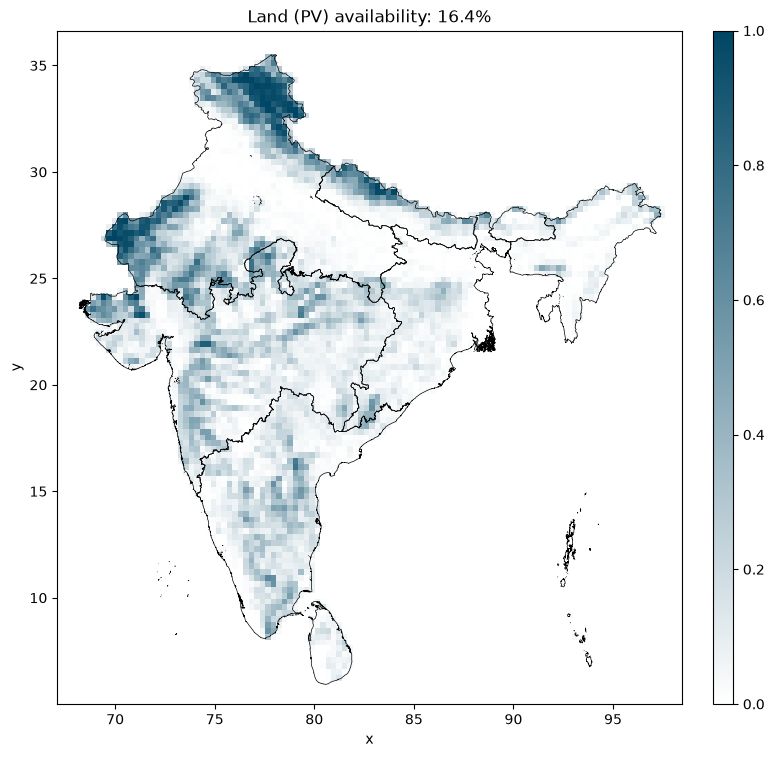

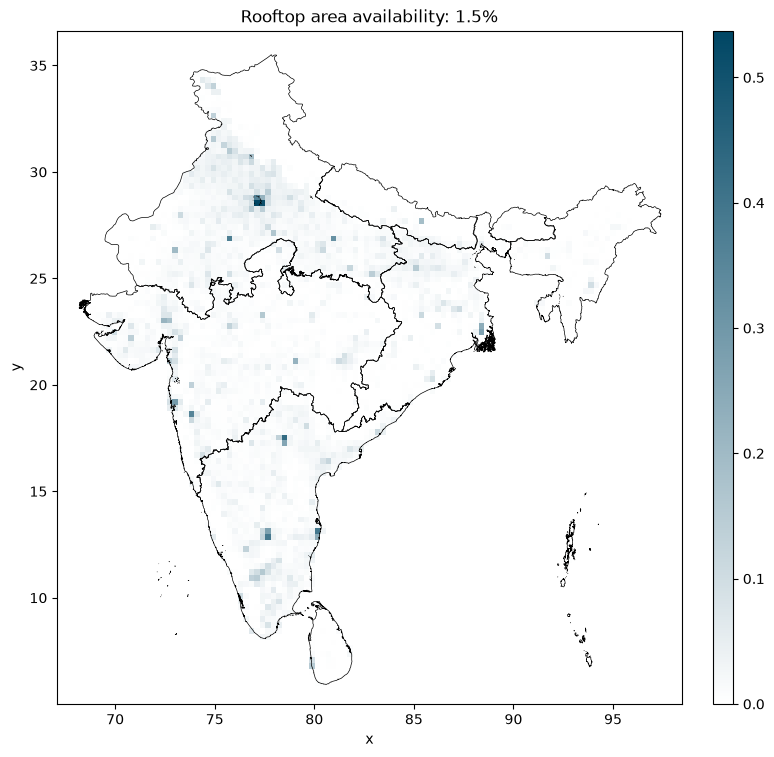

In [37]:
# Controlled by 'run_GIS_analysis_by_region' switch (set in the config cell).
if run_GIS_analysis_by_region:
    # Memory-safe: process every region one at a time. Saves per-region + combined
    # CSVs, returns the stitched availability map + usable coords (land/rooftop/offshore)
    # for the usable-site timeseries below. Passing pv_solar_panel adds a site-quality
    # 'category' (inf/avg/opt) column to the usable-coords CSVs. regions=[] = all.
    combined_potentials, stitched_land, stitched_rooftop, coords_onshore_usable, coords_rooftop_usable, coords_offshore_usable = calculate_potentials_per_region(
        cutout, geo_file, coords_onshore,
        excluder=excluder, cities=cities,
        regions=regions,
        coords_offshore=coords_offshore,
        usable_threshold=usable_threshold, usable_threshold_rooftop=usable_threshold_rooftop,
        offshore_exclude_files=OFFSHORE_EXCLUDE_FILES,
        offshore_exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        offshore_exclude_query=OFFSHORE_EXCLUDE_QUERY,
        pv_cap_per_sqkm=pv_cap_per_sqkm, pv_percent_land_available=pv_percent_land_available,
        wind_cap_per_sqkm=wind_cap_per_sqkm, wind_percent_land_available=wind_percent_land_available,
        rooftop_cap_per_sqkm=rooftop_cap_per_sqkm, rooftop_percent_area_available=rooftop_percent_area_available,
        pv_solar_panel=solar_panel, pv_slope=pv_slope, pv_azimuth=pv_azimuth,
        optimal_tilt=pv_optimal_tilt, rooftop_pv_slope=rooftop_pv_slope, rooftop_pv_azimuth=rooftop_pv_azimuth,
        output_dir=output_dir, filename=filename, color=map_color,
    )
    combined_potentials

### Offshore wind potential

Reuses the EEZ-clipped, depth-classified offshore cells from `get_coords` (so only actual offshore zones are counted). Capacity density and available share can be set per depth class (shallow/transitional = fixed-bottom, deep = floating).

In [38]:
# Offshore wind potential per region and depth class. Uses coords_offshore from
# the timeseries step (EEZ + depth). Densities/availability can be a scalar or a
# dict keyed by depth class. Floating (deep) gets a lower available share here.
offshore_cap_per_sqkm = 5            # MW/km2
offshore_percent_available = {"shallow": 0.10, "transitional": 0.10, "deep": 0.05}

offshore_df = calculate_offshore_potentials(
    cutout, coords_offshore,
    offshore_cap_per_sqkm=offshore_cap_per_sqkm,
    offshore_percent_available=offshore_percent_available,
)
offshore_df

,region,depth_class,Area [km²],Suitable Area Offshore [km²],Offshore Wind Capacity [GW]
0,ER,shallow,26981.514181,2698.151418,13.490757
1,ER,transitional,5251.796310,525.179631,2.625898
2,ER,deep,28008.380626,1400.419031,7.002095
3,ISL,shallow,9131.045576,913.104558,4.565523
4,ISL,transitional,7309.834693,730.983469,3.654917
5,ISL,deep,63105.000550,3155.250027,15.776250
6,LKA,shallow,12876.904019,1287.690402,6.438452
7,LKA,transitional,5530.321035,553.032103,2.765161
8,LKA,deep,16602.754130,830.137706,4.150689
9,SR,shallow,48157.029782,4815.702978,24.078515


In [39]:
# Offshore potential on USABLE sites only (depth + marine-protected-area exclusion),
# for comparison with the theoretical (depth-only) table above. Writes its own CSV.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)

offshore_df_usable = calculate_offshore_potentials(
    cutout, coords_offshore_usable,
    offshore_cap_per_sqkm=offshore_cap_per_sqkm,
    offshore_percent_available=offshore_percent_available,
)
offshore_df_usable.to_csv(os.path.join(output_dir, f"{filename}_potentials_offshore_usable.csv"), index=False)
offshore_df_usable

,region,depth_class,Area [km²],Suitable Area Offshore [km²],Offshore Wind Capacity [GW]
0,ER,shallow,24384.414925,2438.441492,12.192207
1,ER,transitional,5251.796310,525.179631,2.625898
2,ER,deep,28008.380626,1400.419031,7.002095
3,ISL,shallow,9131.045576,913.104558,4.565523
4,ISL,transitional,7309.834693,730.983469,3.654917
5,ISL,deep,63105.000550,3155.250027,15.776250
6,LKA,shallow,12876.904019,1287.690402,6.438452
7,LKA,transitional,5530.321035,553.032103,2.765161
8,LKA,deep,16602.754130,830.137706,4.150689
9,SR,shallow,48157.029782,4815.702978,24.078515


In [40]:
# Standalone offshore export: pivot offshore_df to one row per region with depth-
# class columns + total, and write to CSV. Only needs offshore_df (run the cell
# above first) - does NOT require the per-region combined run.
_off_wide = offshore_df.pivot_table(index="region", columns="depth_class",
                                    values="Offshore Wind Capacity [GW]",
                                    aggfunc="sum", observed=True)
_off_wide.columns = [f"Offshore Wind {c} [GW]" for c in _off_wide.columns]
_off_wide["Offshore Wind Total [GW]"] = _off_wide.sum(axis=1)
_off_wide = _off_wide.reset_index()
_off_wide.to_csv(os.path.join(output_dir, f"{filename}_potentials_offshore.csv"), index=False)
_off_wide

,region,Offshore Wind shallow [GW],Offshore Wind transitional [GW],Offshore Wind deep [GW],Offshore Wind Total [GW]
0,ER,13.490757,2.625898,7.002095,23.118750
1,ISL,4.565523,3.654917,15.776250,23.996690
2,LKA,6.438452,2.765161,4.150689,13.354301
3,SR,24.078515,20.449142,24.323098,68.850755
4,WR,29.234650,21.512534,30.889661,81.636844


usable offshore cells: 652 of 2918


<Axes: title={'center': 'Usable offshore cells by depth_class'}>

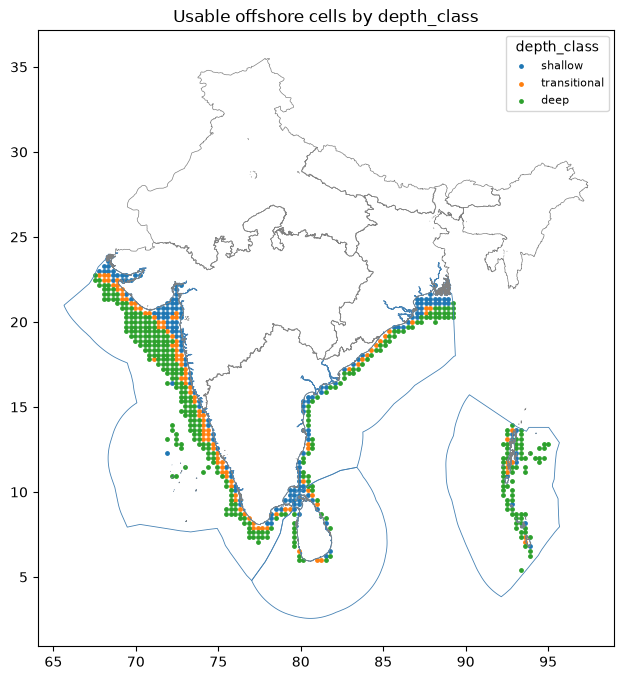

In [41]:
# Usable offshore sites across ALL regions come from the loop above
# (coords_offshore_usable), already filtered by depth AND marine protected areas.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)
print(f"usable offshore cells: {len(coords_offshore_usable)} of {len(coords_offshore)}")

# Offshore wind capacity factors on usable sites only (shallow/transitional/deep):
wind_off_shallow_u, wind_off_trans_u, wind_off_deep_u = wind_offshore_capacity_factors(
    cutout, coords_offshore_usable, offshore_turbine,
    timeframe=timeframe, filename=filename+"_usable",
    write_raw_data=False, output_dir=output_dir)

# Map of the usable offshore cells, coloured by depth class:
plot_offshore_map(coords_offshore_usable, shapes=shapes, offshore_file=offshore_file, color_by="depth_class")

### Capacity-factor timeseries on usable sites only

Restrict the RES timeseries to cells that survive the exclusion layers. 
`usable_onshore_coords` keeps cutout cells whose availability > threshold (from the 
availability matrix); feed those into the normal PV / onshore-wind functions, which 
still split into opt/avg/inf. `usable_offshore_coords` keeps buildable offshore cells 
(depth within limits) for the offshore-wind timeseries.

In [42]:
# Usable onshore sites across ALL regions come from the memory-safe loop above
# (coords_onshore_usable). For a quick single-region test instead, use:
#   coords_onshore_usable = usable_onshore_coords(AvailabilityMatrix, coords_onshore)
print(f"usable onshore cells: {len(coords_onshore_usable)} of {len(coords_onshore)}")
print(f"usable rooftop cells: {len(coords_rooftop_usable)} of {len(coords_onshore)}")

# Utility-scale PV on usable land (per-cell optimal tilt if pv_optimal_tilt):
pv_inf_u, pv_avg_u, pv_opt_u = pv_capacity_factors(cutout, coords_onshore_usable, solar_panel,
                                                   pv_slope=pv_slope, pv_azimuth=pv_azimuth,
                                                   optimal_tilt=pv_optimal_tilt,
                                                   timeframe=timeframe, filename=filename+"_usable",
                                                   write_raw_data=False, output_dir=output_dir)

# Rooftop PV: separate category, only rooftop-available cells, own fixed slope/azimuth
# (roofs dictate orientation, so no optimal-tilt here). Label "pv_rooftop".
pv_roof_inf, pv_roof_avg, pv_roof_opt = pv_capacity_factors(cutout, coords_rooftop_usable, solar_panel,
                                                            pv_slope=rooftop_pv_slope, pv_azimuth=rooftop_pv_azimuth,
                                                            tech_label="pv_rooftop",
                                                            timeframe=timeframe, filename=filename+"_usable",
                                                            write_raw_data=False, output_dir=output_dir)

# Onshore wind capacity factors on usable land:
wind_inf_u, wind_avg_u, wind_opt_u = wind_onshore_capacity_factors(cutout, coords_onshore_usable, onshore_turbine,
                                                                   timeframe=timeframe, filename=filename+"_usable",
                                                                   write_raw_data=False, output_dir=output_dir)

usable onshore cells: 3422 of 3982
usable rooftop cells: 181 of 3982


usable offshore cells: 652 of 2918


<Axes: title={'center': 'Usable offshore cells by depth_class'}>

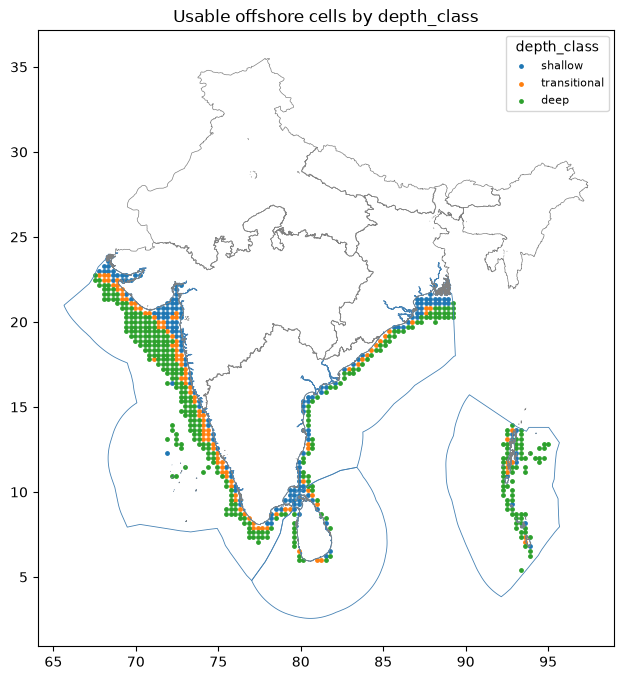

In [43]:
# Usable offshore sites across ALL regions come from the loop above
# (coords_offshore_usable), already filtered by depth AND marine protected areas.
if 'coords_offshore_usable' not in dir() or coords_offshore_usable is None:
    coords_offshore_usable = usable_offshore_coords(coords_offshore,
        exclude_files=OFFSHORE_EXCLUDE_FILES, exclude_layer=OFFSHORE_EXCLUDE_LAYER,
        exclude_query=OFFSHORE_EXCLUDE_QUERY)
print(f"usable offshore cells: {len(coords_offshore_usable)} of {len(coords_offshore)}")

# Offshore wind capacity factors on usable sites only (shallow/transitional/deep):
wind_off_shallow_u, wind_off_trans_u, wind_off_deep_u = wind_offshore_capacity_factors(
    cutout, coords_offshore_usable, offshore_turbine,
    timeframe=timeframe, filename=filename+"_usable",
    write_raw_data=False, output_dir=output_dir)

# Map of the usable offshore cells, coloured by depth class:
# (India EEZ is open ocean - no enclosed sea to strip, so the raw EEZ outline is used.)
plot_offshore_map(coords_offshore_usable, shapes=shapes,
                  offshore_file=offshore_file, color_by="depth_class")

## Plot usable sites

Maps of the developable cells per technology, colour-coded by site-quality class (inf / avg / opt) for onshore and rooftop, and by depth class for offshore. The `category` column is written into the usable-coords CSVs by the memory-safe potentials cell.

**Sensitivity:** the minimum developable share per cell is `usable_threshold` (and `usable_threshold_rooftop`) in the parameters cell. Raise it (e.g. 0.02, 0.03) to drop low-availability cells, then re-run the potentials + this cell.

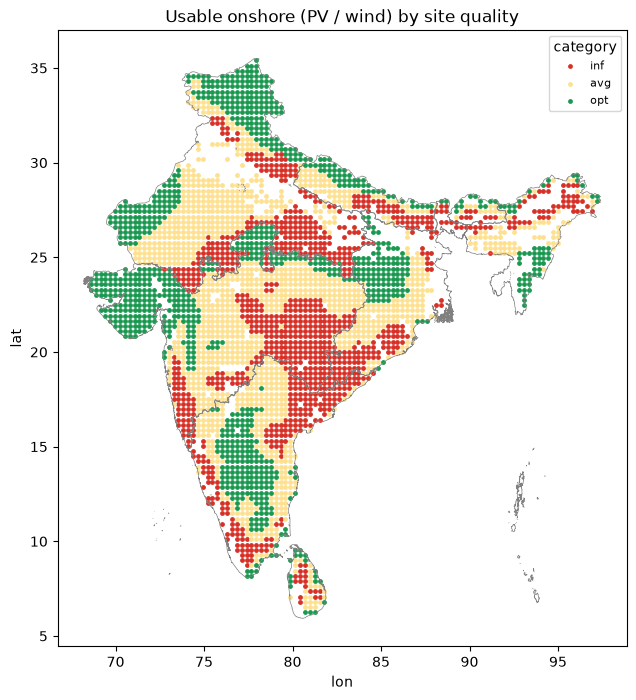

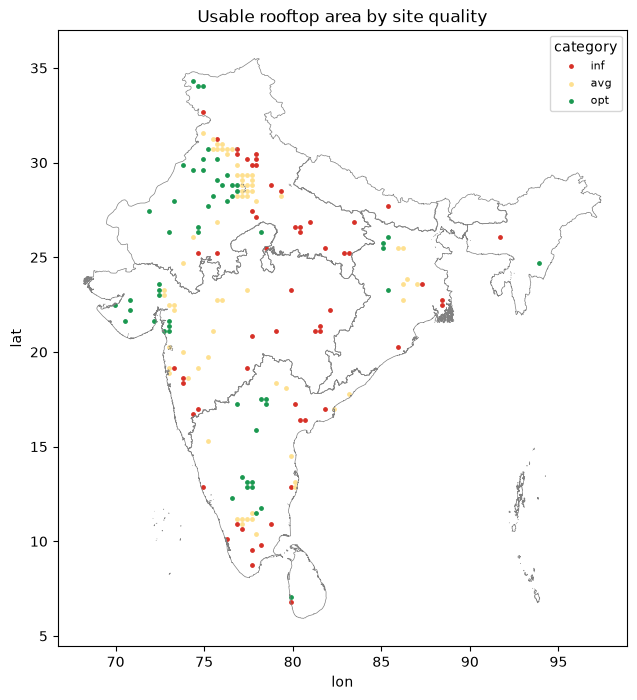

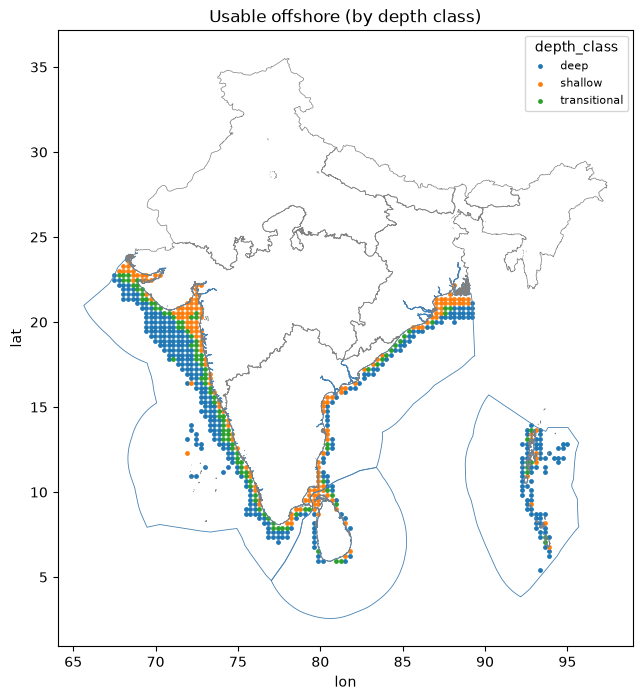

In [44]:
# Maps of usable sites per technology, colour-coded. Onshore/rooftop use the
# site-quality 'category' column (inf/avg/opt) now stored in the usable-coords;
# offshore uses depth class. Guarded so missing/empty layers are skipped.
_region_shapes = shapes if 'shapes' in dir() else None

if 'coords_onshore_usable' in dir() and coords_onshore_usable is not None and len(coords_onshore_usable):
    plot_usable_coords(coords_onshore_usable, shapes=_region_shapes,
                       color_by='category', title='Usable onshore (PV / wind) by site quality')

if 'coords_rooftop_usable' in dir() and coords_rooftop_usable is not None and len(coords_rooftop_usable):
    plot_usable_coords(coords_rooftop_usable, shapes=_region_shapes,
                       color_by='category', title='Usable rooftop area by site quality')

if 'coords_offshore_usable' in dir() and coords_offshore_usable is not None and len(coords_offshore_usable):
    plot_usable_coords(coords_offshore_usable, shapes=_region_shapes,
                       boundary_file=offshore_file, color_by='depth_class',
                       title='Usable offshore (by depth class)')